Extracting dataset...
Dataset ready!
Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.5075 - loss: 0.7219 - val_accuracy: 0.5000 - val_loss: 0.6923
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 200s 1s/step - accuracy: 0.5015 - loss: 0.6982 - val_accuracy: 0.5930 - val_loss: 0.6925
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - accuracy: 0.5105 - loss: 0.6937 - val_accuracy: 0.5580 - val_loss: 0.6849
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.5515 - loss: 0.6922 - val_accuracy: 0.5180 - val_loss: 0.6821
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.5910 - loss: 0.6757 - val_accuracy: 0.6580 - val_loss: 0.6342
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6040 - loss: 0.6606 - val_accuracy: 0.6410 - val_loss: 0.6345
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.6200 - loss: 0.6531 - val_accuracy: 0.6770 - val_loss: 0.6255
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.6365 - loss: 0.6410 - val_accu

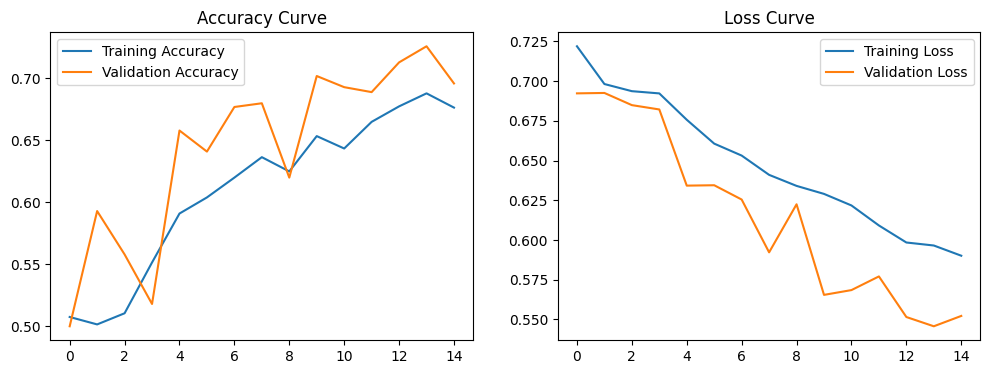

50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 349ms/step


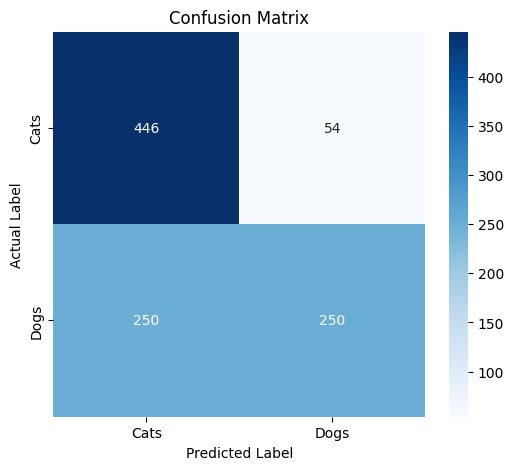

In [6]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt
import numpy as np
import os
import urllib.request
import zipfile
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 1. Download and Extract the Dataset (UPDATED URL)
url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"
file_name = "cats_and_dogs_filtered.zip"

print("Downloading dataset...")
urllib.request.urlretrieve(url, file_name)

print("Extracting dataset...")
with zipfile.ZipFile(file_name, 'r') as zip_ref:
    zip_ref.extractall()

base_dir = 'cats_and_dogs_filtered'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
print("Dataset ready!")

# 2. Data Generators & Augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=(150, 150), batch_size=20, class_mode='binary'
)

validation_generator = test_datagen.flow_from_directory(
    validation_dir, target_size=(150, 150), batch_size=20, class_mode='binary', shuffle=False
)

# 3. CNN Layers
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150, 150, 3)),
    MaxPooling2D(2, 2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])

# 4. Model Fitting
history = model.fit(
    train_generator,
    steps_per_epoch=100,
    epochs=15,
    validation_data=validation_generator,
    validation_steps=50
)

# 5. Validation Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy Curve')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss Curve')
plt.show()

# 6. Confusion Matrix
Y_pred = model.predict(validation_generator)
y_pred = np.where(Y_pred > 0.5, 1, 0)
cm = confusion_matrix(validation_generator.classes, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cats', 'Dogs'], yticklabels=['Cats', 'Dogs'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()